# 3. Estimate the XYZ spectral matrix

## Goal
Recover the **full stationary XYZ spectral matrix**, including its response
dips, from the time series in notebook 1. A simple orbit-derived sine reference
places the dips; the **ordinary multivariate LogPSplinePSD model** learns a
positive-definite matrix correction around it.

We run **two NUTS chains with analytically marginalised theta**. The six
Gaussian cross-channel coefficient fields are integrated out while sampling,
then restored as joint conditional draws for reconstruction. This uses the
construction in [Vajpeyi et al.](https://arxiv.org/abs/2607.04833); it is a
teaching run, not a reproduction of the paper's uncertainty study.

## Setup
Run notebook 1 first. Both the known geometry and the time series are saved
there. The reference uses the geometry, never the injected spline correction.
Its first-generation envelope is frozen on day 0; the generator uses the full
midweek geometry, so the two references need not agree exactly.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from log_psplines import SpectralMatrix, TimeSeries, fit, local_wishart_grid
from log_psplines.diagnostics import sampling_diagnostics
from scipy.signal import get_window

from lisa_case_studies.notebook_tools import (
    COLORS,
    matrix_errors,
    plot_nuts_traces,
    reference_config,
    style,
)
from lisa_case_studies.reference_matrix import (
    adaptive_partition,
    coefficient_data,
    matrix_mean,
    pool_log_frequency,
)
from lisa_case_studies.sine_reference import sine_gains, sine_reference_for
from lisa_case_studies.tutorial_data import MatrixSimulation, load_data, workspace

style()
data = load_data("stationary_xyz")
series = TimeSeries(data["xyz"], data["time"])

## Step 1 — Supply the approximate sine reference
Known four-link loop times $\tau_j$ place the dominant XYZ response nulls:

$$g_j(f)=2i e^{-i\pi f\tau_j}\sin(\pi f\tau_j),\qquad
S_0(f)=\operatorname{diag}(g)B_\star(f)\operatorname{diag}(g)^\dagger.$$

$B_\star$ is a fixed, full Michelson covariance envelope calculated once from
the initial Keplerian geometry. Only the loop sine factors track the analysis
geometry. It approximates the full response; no dip locations or instrument
noise levels are estimated in this notebook.

With $L_0=\operatorname{chol}(S_0)$, the model is
$S(f)=L_0(f)R(f)L_0(f)^\dagger$. The full multivariate spline $R$, rather than
three independent PSD splines, corrects the reference.

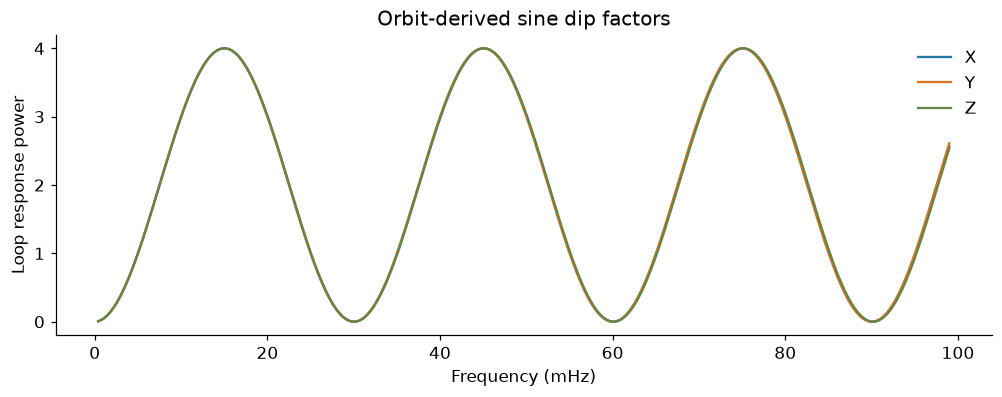

In [2]:
block_length = len(data["time"]) // 8
block_simulation = MatrixSimulation(
    block_length, float(data["dt"]), np.array([0.0]), data["light_times"][None]
)
sine_reference = sine_reference_for(block_simulation)
dip_frequency = np.linspace(0.4e-3, 99e-3, 3000)
gains = sine_gains(dip_frequency, data["light_times"])
fig, ax = plt.subplots(layout="constrained")
for j, channel in enumerate("XYZ"):
    ax.plot(
        dip_frequency * 1000,
        abs(gains[:, j]) ** 2,
        color=COLORS[channel],
        label=channel,
    )
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="Loop response power",
    title="Orbit-derived sine dip factors",
)
ax.legend(frameon=False)
plt.show()

## Step 2 — Form and whiten the Fourier statistics
The public `local_wishart_grid` function forms eight Hann-tapered blocks in
physical one-sided PSD units. Apply the same window to the nominal matrix
reference before whitening each complex XYZ vector. Sum the **unsmoothed**
outer products and keep the actual count of eight blocks.

The stationary circulant block reference is a finite-window approximation to
the original long record. Windowing and frequency dependence also mean that
the correction and observation operator need not commute. The inferred target
is a multivariate Whittle approximation, not an exact time-domain likelihood.

In [3]:
grid = local_wishart_grid(series, segment_length=block_length, window="hann")
band = (grid.frequency >= 0.4e-3) & (grid.frequency <= 99e-3)
frequency = grid.frequency[band]
taper = get_window("hann", block_length, fftbins=True)
window_reference = sine_reference.window_references({"hann": taper})["hann"][1:-1]
# MatrixSimulation uses sqrt(2*dt/N); local_wishart_grid uses sqrt(2*dt/sum(w**2)).
window_reference *= block_length / np.sum(taper**2)
coefficients = np.transpose(grid.U[..., 0][:, band, :], (1, 2, 0))
white = np.linalg.solve(np.linalg.cholesky(window_reference[band]), coefficients)
statistics = coefficient_data(white, frequency, enbw=grid.enbw)
assert statistics.Nb == 8
partition = adaptive_partition(
    statistics, tolerance=0.25, max_width=32, pilot_window=31
)
pooled = pool_log_frequency(statistics, partition)
pd.DataFrame(
    {
        "Native frequencies": [len(frequency)],
        "Adaptive aggregates": [partition.Nc],
        "Blocks": [statistics.Nb],
    }
)

,Native frequencies,Adaptive aggregates,Blocks
0,4039,181,8


## Step 3 — Run the library's marginalised NUTS model
The ordinary stationary multivariate model writes
$R^{-1}=T^\dagger D^{-1}T$. Three log-diagonal fields and six real/imaginary
theta fields describe the full matrix. Gaussian theta coefficients are
integrated exactly under the library prior. NUTS samples the log-diagonal
weights and all smoothing scales; reconstruction restores theta conditionals.

The derivative penalties, proper ridge and smoothing-scale priors are the
unchanged library defaults. The spline basis and adaptive partition are fixed
using the observed data before the fit. Injected truth is not used to select
knots, priors or NUTS settings.

In [4]:
config, components = reference_config(pooled, seed=17)
result = fit(pooled, config)
assert result.metadata["method"] == "nuts"
assert result.metadata["theta_parameterization"] == "marginalized"
assert result.vi is None
restored = [name for name in result.posterior if name.startswith("weights_theta_")]
assert len(restored) == 6
assert not any(name.endswith("_raw") for name in restored)

|00:01| LogPSpline | INFO | Spline model: SpectralComponents(channels=3, knots=10, degree=3, penaltyOrder=2, N=181, basis_shapes=[(181, 12), (181, 12), (181, 12), (181, 12), (181, 12), (181, 12), (181, 12), (181, 12), (181, 12)])


W1106 16:49:20.309590 2534873 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


## Step 4 — Check the sampler before looking at truth
Inspect both chains and the diagnostic table for every sampled and restored
field. Low R-hat, adequate bulk/tail ESS, zero divergences and no tree-depth
saturation support numerical exploration of this target. They do not establish
coverage under the approximate observation model.

,factor,divergences,rhat_max,ess_bulk_min,ess_tail_min,max_treedepth_hits,step_size,n_draws
0,0,0,1.003,992.563,768.925,0,0.320,2000
1,1,0,1.005,1621.433,1206.723,0,0.350,2000
2,2,0,1.006,787.722,919.575,0,0.315,2000


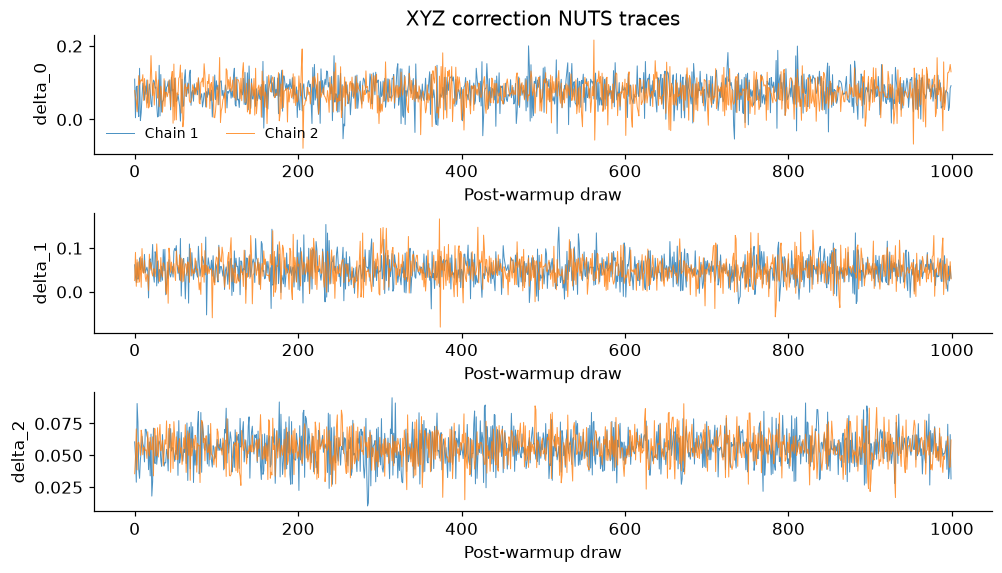

In [5]:
nuts_checks = pd.DataFrame(sampling_diagnostics(result)["nuts"])
display(nuts_checks.round(3))
plot_nuts_traces(result, label="XYZ correction")
plt.show()
assert nuts_checks["divergences"].sum() == 0
assert nuts_checks["rhat_max"].max() < 1.05
assert nuts_checks["ess_bulk_min"].min() > 100
assert nuts_checks["ess_tail_min"].min() > 100
assert nuts_checks["max_treedepth_hits"].sum() == 0

## Step 5 — Reconstruct the physical channel PSDs
Evaluate on a fixed native-frequency support and undo the reference
transformation. The point estimate averages complete positive-definite
matrices, including restored theta, rather than entrywise medians.
Truth first enters here for final reconstruction assessment.

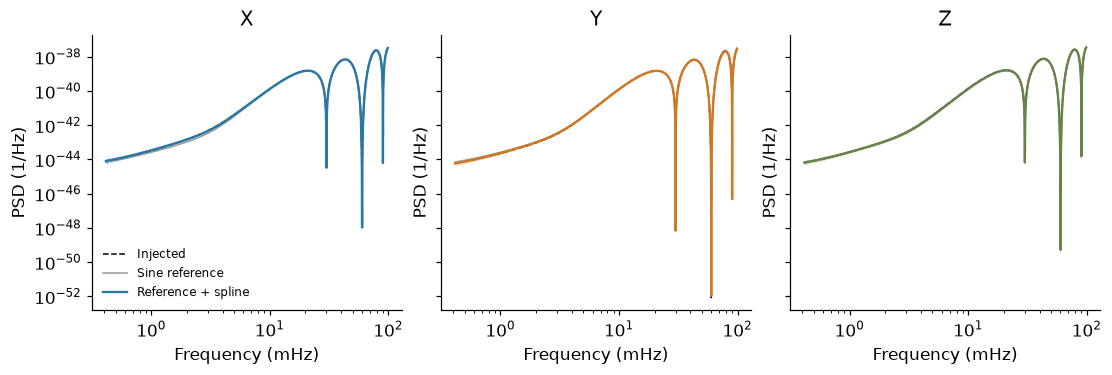

In [6]:
probe = np.unique(
    np.r_[
        np.rint(
            np.geomspace(frequency[0], frequency[-1], 400)
            * block_length
            * float(data["dt"])
        ).astype(int),
        *[
            np.flatnonzero(abs(block_simulation.frequency - f0) < 0.6e-3)
            for f0 in (0.03, 0.06, 0.09)
        ],
    ]
)
evaluation_frequency = block_simulation.frequency[probe]
coordinate = np.clip(
    np.log(evaluation_frequency / frequency[0]) / np.log(frequency[-1] / frequency[0]),
    0,
    1,
)
correction = matrix_mean(result.posterior, components, coordinate)
factor = sine_reference.reference_factor(np.array([0.0]), evaluation_frequency)[0]
nominal = factor @ factor.conj().swapaxes(-1, -2)
estimate = factor @ correction @ factor.conj().swapaxes(-1, -2)
truth = block_simulation.spectrum(np.array([0.0]), evaluation_frequency)[0]
# Restore physical units on the fitting support for posterior bands.
fit_factor = sine_reference.reference_factor(np.array([0.0]), partition.f_coarse)[0]
physical_draws = (
    fit_factor[None, None]
    @ np.asarray(result.spectral_density)
    @ fit_factor.conj().swapaxes(-1, -2)[None, None]
)
auto_bands = np.percentile(
    np.diagonal(physical_draws, axis1=-2, axis2=-1).real, [5, 95], axis=(0, 1)
)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True, layout="constrained")
for j, (ax, channel) in enumerate(zip(axes, "XYZ", strict=True)):
    ax.loglog(
        evaluation_frequency * 1000, truth[:, j, j].real, "k--", lw=1, label="Injected"
    )
    ax.loglog(
        evaluation_frequency * 1000,
        nominal[:, j, j].real,
        color="0.6",
        lw=1,
        label="Sine reference",
    )
    ax.loglog(
        evaluation_frequency * 1000,
        estimate[:, j, j].real,
        color=COLORS[channel],
        label="Reference + spline",
    )
    ax.fill_between(
        partition.f_coarse * 1000,
        auto_bands[0, :, j],
        auto_bands[1, :, j],
        color=COLORS[channel],
        alpha=0.18,
    )
    ax.set(xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title=channel)
axes[0].legend(fontsize=8, frameon=False)
plt.show()

### Read the correction as a residual
The broad PSD range can hide differences between nearly overlapping curves.
Plot signed log ratios on the same fixed support: grey is the approximate
sine reference and colour is the learned correction. Remaining structure
near a null can reflect the frozen-envelope or finite-window approximation;
NUTS diagnostics do not remove that model mismatch.

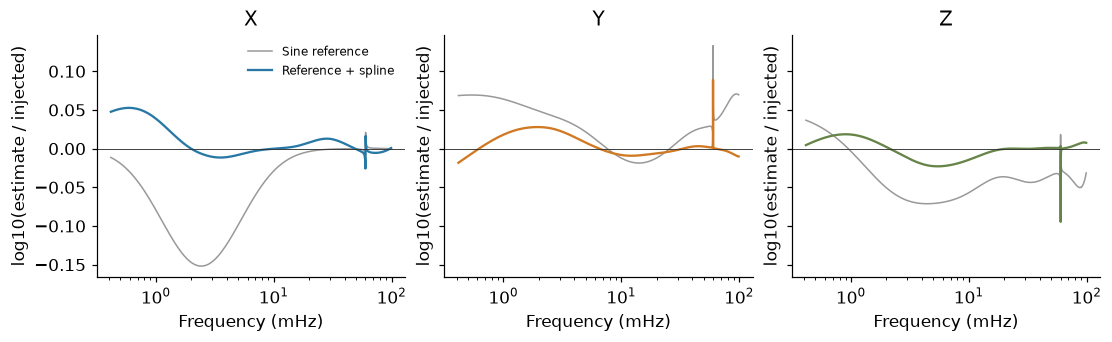

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True, layout="constrained")
for j, (ax, channel) in enumerate(zip(axes, "XYZ", strict=True)):
    ax.semilogx(
        evaluation_frequency * 1000,
        np.log10(nominal[:, j, j].real / truth[:, j, j].real),
        color="0.6",
        lw=1,
        label="Sine reference",
    )
    ax.semilogx(
        evaluation_frequency * 1000,
        np.log10(estimate[:, j, j].real / truth[:, j, j].real),
        color=COLORS[channel],
        label="Reference + spline",
    )
    ax.axhline(0, color="0.2", lw=0.6)
    ax.set(xlabel="Frequency (mHz)", ylabel="log10(estimate / injected)", title=channel)
axes[0].legend(fontsize=8, frameon=False)
plt.show()

Shading is the central 90% posterior interval under the approximate Whittle
model, including restored conditional theta. It does not include reference
geometry uncertainty or establish repeated-data coverage.

## Step 6 — Inspect the complex cross spectrum
$S_{XY}=E[\widetilde X\widetilde Y^*]$ contains both magnitude and phase.
The correction is free to change both; diagonal-only estimation would lose
this information.

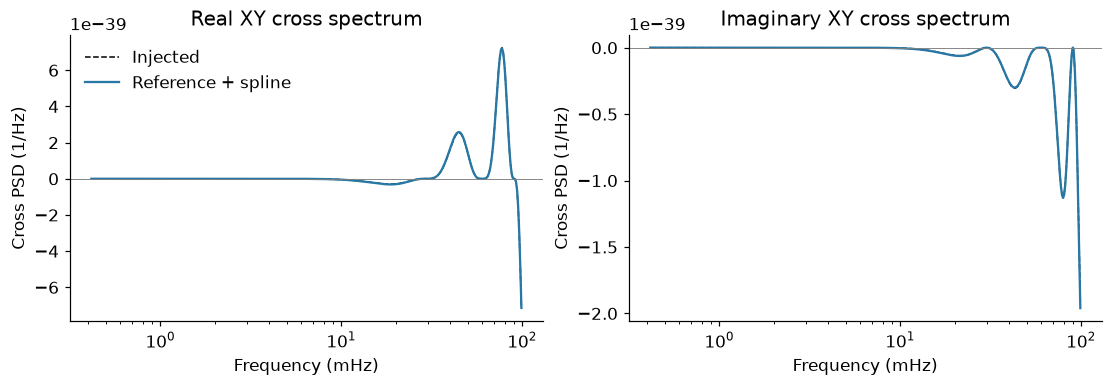

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
for ax, part, title in zip(
    axes,
    (np.real, np.imag),
    ("Real XY cross spectrum", "Imaginary XY cross spectrum"),
    strict=True,
):
    ax.semilogx(
        evaluation_frequency * 1000, part(truth[:, 0, 1]), "k--", lw=1, label="Injected"
    )
    ax.semilogx(
        evaluation_frequency * 1000,
        part(estimate[:, 0, 1]),
        color=COLORS["X"],
        label="Reference + spline",
    )
    ax.axhline(0, color="0.5", lw=0.6)
    ax.set(xlabel="Frequency (mHz)", ylabel="Cross PSD (1/Hz)", title=title)
axes[0].legend(frameon=False)
plt.show()

## Step 7 — Inspect coherence
Magnitude-squared coherence is $|S_{ij}|^2/(S_{ii}S_{jj})$. Compute it from
the same whole point matrix as the auto/cross spectra.

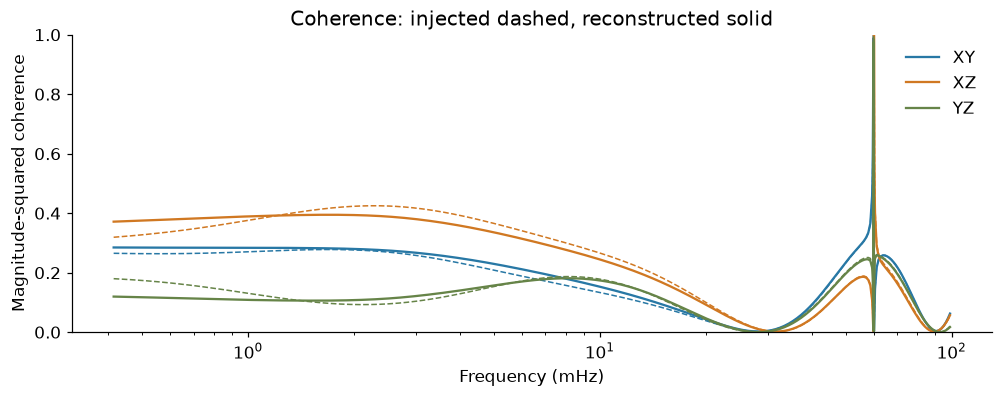

In [9]:
coherence_fit = np.asarray(SpectralMatrix.coherence(estimate))
coherence_truth = np.asarray(SpectralMatrix.coherence(truth))
fig, ax = plt.subplots(layout="constrained")
for (j, k), label, color in zip(
    ((0, 1), (0, 2), (1, 2)),
    ("XY", "XZ", "YZ"),
    (COLORS["X"], COLORS["Y"], COLORS["Z"]),
    strict=True,
):
    ax.semilogx(
        evaluation_frequency * 1000,
        coherence_truth[:, j, k],
        color=color,
        ls="--",
        lw=1,
    )
    ax.semilogx(
        evaluation_frequency * 1000, coherence_fit[:, j, k], color=color, label=label
    )
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="Magnitude-squared coherence",
    ylim=(0, 1),
    title="Coherence: injected dashed, reconstructed solid",
)
ax.legend(frameon=False)
plt.show()

## Checks and next steps
Verify Hermitian symmetry and positive definiteness. Compare the fixed sine
reference with its learned full-matrix correction on identical support.
The grid combines a logarithmic overview with all native bins within
0.6 mHz of each nominal null; each displayed grid point has equal weight.
These errors assess point reconstruction and do not test posterior coverage.
[Notebook 4](04_short_xyz_gaps.ipynb) applies the same idea to evolving geometry
and gaps, with an exact joint selected-feature covariance benchmark.

In [10]:
np.testing.assert_allclose(
    estimate, estimate.conj().swapaxes(-1, -2), rtol=1e-10, atol=1e-55
)
assert np.linalg.eigvalsh(estimate).min() > 0
error_table = pd.DataFrame(
    {
        "Sine reference": matrix_errors(nominal, truth),
        "Reference + spline": matrix_errors(estimate, truth),
    }
).T
display(error_table.round(4))
np.savez_compressed(
    workspace() / "stationary_xyz_nuts_recovery.npz",
    frequency=evaluation_frequency,
    estimate=estimate,
    reference=nominal,
    truth=truth,
)
nuts_checks.to_json(
    workspace() / "stationary_xyz_nuts_diagnostics.json", orient="records", indent=2
)
error_table.to_json(
    workspace() / "stationary_xyz_nuts_errors.json", orient="index", indent=2
)

,Auto log10 RMSE,Complex cross RMSE
Sine reference,0.0530,0.1008
Reference + spline,0.0141,0.0304
